# ENSO statistics

## Figure 2: ENSO characteristics

In [1]:
import json
from pathlib import Path
import cmip6_results
import matplotlib.pyplot as plt
import numpy as np
import plotstyle as ps
import xarray as xr
from scipy import stats

ps.apply()

In [2]:
DATA = Path("../data")
SERIES = DATA / "nino34_series.nc"
RUNS = tuple(ps.ENSEMBLES["SamudrACE"])
WINDOW = 150
PERIODS = (1.2, 12.0)
POWER_LEVELS = [0.25, 0.5, 1, 2, 4, 8, 16]
METRICS = [
    ("EnsoAmpl", "Amplitude", "°C"),
    ("EnsoSeasonality", "Seasonality", "NDJ/MAM"),
    ("EnsoSstSkew", "Skewness", ""),
    ("EnsoDuration", "Duration", "months"),
    ("EnsoSstDiversity", "Diversity", "° lon"),
]


def series() -> dict[str, np.ndarray]:
    ds = xr.open_dataset(SERIES)
    out = {}
    for k in (*RUNS, "GFDL-CM4", "ORAS5"):
        out[k] = (ds[k].values.astype(float), ds[f"year_{k}"].values, ds[f"month_{k}"].values)
    return out


def welch(series: np.ndarray, seg_years: int = 100) -> tuple[np.ndarray, np.ndarray]:
    series = series[np.isfinite(series)]
    series = series - series.mean()
    seg = min(seg_years * 12, series.size)
    n = max(series.size // seg, 1)
    power = 0.0
    for i in range(n):
        chunk = series[i * seg : (i + 1) * seg] * np.hanning(seg)
        power = power + np.abs(np.fft.rfft(chunk)) ** 2
    power = power / n
    freq = np.fft.rfftfreq(seg, d=1 / 12.0)
    return freq[1:], (freq[1:] * power[1:]) / np.trapezoid(power[1:], freq[1:])


def metrics() -> dict[str, dict]:
    core = json.loads((DATA / "core_metrics.json").read_text())
    alpha = json.loads((DATA / "alpha.json").read_text())
    out = {}
    for key, entry in core.items():
        out[key] = {"full": dict(entry["full_record"]), "segments": dict(entry["segments"])}
        out[key]["full"]["alpha"] = alpha[key]["full_record"]["alpha"]
        out[key]["segments"]["alpha"] = alpha[key].get("segments", {}).get("alpha", [])
    obs = ps.obs_bootstrap("core") | {"alpha": ps.obs_bootstrap("alpha").get("alpha")}
    out["ORAS5"]["range"] = {k: v for k, v in obs.items() if isinstance(v, list)}
    cmip6_alpha = cmip6_results.alpha()
    for key, entry in cmip6_results.core().items():
        full = dict(entry["full_record"])
        full["alpha"] = cmip6_alpha.get(key, {}).get("full_record", {}).get("alpha", np.nan)
        out[key] = {"full": full, "segments": {}}
    return out


def wavelet(x: np.ndarray, dt: float = 1 / 12, dj: float = 1 / 16, omega0: float = 6.0,
            dof: int = 2):
    x = x - x.mean()
    n = x.size
    pad = int(2 ** np.ceil(np.log2(n)) * 2)
    fourier = 4 * np.pi / (omega0 + np.sqrt(2 + omega0**2))
    s0, s1 = PERIODS[0] / fourier, PERIODS[1] / fourier
    scales = s0 * 2 ** (np.arange(int(np.log2(s1 / s0) / dj) + 1) * dj)
    k = 2 * np.pi * np.fft.fftfreq(pad, dt)
    xhat = np.fft.fft(x, pad)
    psi = (np.pi ** -0.25) * np.sqrt(2 * np.pi * scales[:, None] / dt) \
        * np.exp(-0.5 * (scales[:, None] * k[None, :] - omega0) ** 2) * (k[None, :] > 0)
    w = np.fft.ifft(xhat[None, :] * psi, axis=1)[:, :n]
    power = np.abs(w) ** 2
    period = fourier * scales
    edge = np.concatenate([np.arange(1, (n + 1) // 2 + 1), np.arange(n // 2, 0, -1)]) * dt
    coi = fourier / np.sqrt(2) * edge
    r1 = np.corrcoef(x[:-1], x[1:])[0, 1]
    red = (1 - r1**2) / (1 + r1**2 - 2 * r1 * np.cos(2 * np.pi * dt / period))
    level = x.var() * red * stats.chi2.ppf(0.95, dof) / dof
    return power, period, coi, level


def wavelet_panel(ax, xs, years, label, letter, show_x=True):
    out = [wavelet(x, dof=2 * len(xs)) for x in xs]
    power = np.mean([o[0] for o in out], axis=0)
    level = np.mean([o[3] for o in out], axis=0)
    period, coi = out[0][1], out[0][2]
    x = xs[0]
    t = years[0] + np.arange(x.size) / 12
    m = ax.contourf(t, period, power, levels=POWER_LEVELS, cmap="YlOrRd", extend="both")
    m.set_rasterized(True)
    ax.contour(t, period, power / level[:, None], levels=[1], colors=ps.INK, linewidths=0.6)
    ax.fill_between(t, coi, PERIODS[1] * 2, facecolor="none", edgecolor=ps.MUTED, hatch="xx",
                    lw=0, alpha=0.6)
    ax.set_yscale("log")
    ax.set_ylim(PERIODS[1], PERIODS[0] * 1.25)
    ax.set_yticks([1.5, 2, 3, 4, 6, 10])
    ax.set_yticklabels(["1.5", "2", "3", "4", "6", "10"])
    ax.set_xlim(t[0], t[-1])
    ax.tick_params(labelbottom=show_x)
    ax.set_ylabel("period (yr)")
    ps.panel_label(ax, label, letter, dy=1.03)
    return m


def spectrum_panel(ax, members, cmip6_rows, cmip6_periods, colour, letter, obs=None):
    if obs:
        ps.obs_band(ax, 1 / np.asarray(obs["frequency"]), obs["spectrum"], horizontal=True)
    lo, med, hi = np.nanpercentile(cmip6_rows, [10, 50, 90], axis=0)
    ax.fill_betweenx(cmip6_periods, lo, hi, color=ps.COLORS["CMIP6"], alpha=0.28, lw=0)
    ax.plot(med, cmip6_periods, color=ps.COLORS["CMIP6"], lw=1.2)
    spectra = [welch(m) for m in members]
    f, p = spectra[0][0], np.mean([s[1] for s in spectra], axis=0)
    ax.plot(p, 1 / f, color=colour, lw=1.6)
    ax.set_yscale("log")
    ax.set_ylim(PERIODS[1], PERIODS[0] * 1.25)
    ax.set_yticks([1.5, 2, 3, 4, 6, 10])
    ax.set_yticklabels([])
    ax.set_xlim(0, 3.4)
    ax.grid(axis="x", color=ps.GRID, lw=0.6)
    ax.tick_params(labelbottom=False)
    ps.panel_label(ax, "", letter, dy=1.03)


def scorecard_panel(ax, data, letter):
    ps.scorecard(ax, data, METRICS, RUNS)
    n = len([k for k in data if k.startswith("CMIP6_")])
    ps.panel_label(ax, "CLIVAR metrics against CMIP6", letter, dx=-0.5, dy=1.02)


def month_panel(ax, by_month, cmip6_rows, letter, obs=None):
    months = np.arange(1, 13)
    if obs:
        ps.obs_band(ax, months, obs)
    lo, med, hi = np.nanpercentile(np.asarray(cmip6_rows, float), [10, 50, 90], axis=0)
    ax.fill_between(months, lo, hi, color=ps.COLORS["CMIP6"], alpha=0.28, lw=0)
    ax.plot(months, med, color=ps.COLORS["CMIP6"], lw=1.2)
    for key, vals in by_month.items():
        ax.plot(months, vals, color=ps.COLORS[key], lw=1.6)
    ax.set_xticks(months)
    ax.set_xticklabels(list("JFMAMJJASOND"))
    ax.set_xlim(0.6, 12.4)
    ax.set_ylabel("°C")
    ps.panel_label(ax, "Std. dev. by calendar month", letter, dy=1.03)
    ps.tidy(ax)


def acf(x: np.ndarray, lags: int = 144) -> np.ndarray:
    x = x[np.isfinite(x)] - np.nanmean(x)
    full = np.correlate(x, x, "full")[x.size - 1:] / (x @ x)
    return full[: lags + 1]


def acf_panel(ax, curves, cmip6_rows, letter, obs=None):
    lags = np.arange(145)
    if obs:
        ps.obs_band(ax, lags, np.asarray(obs)[:, : lags.size])
    lo, med, hi = np.nanpercentile(np.asarray(cmip6_rows, float), [10, 50, 90], axis=0)
    ax.fill_between(lags, lo, hi, color=ps.COLORS["CMIP6"], alpha=0.28, lw=0)
    ax.plot(lags, med, color=ps.COLORS["CMIP6"], lw=1.2)
    for key, ac in curves.items():
        ax.plot(lags, ac[: lags.size], color=ps.COLORS[key], lw=1.6)
    ax.axhline(0, color=ps.GRID, lw=0.8)
    ax.set_xticks([0, 36, 72, 108, 144])
    ax.set_xlim(0, 144)
    ax.set_xlabel("lag (months)")
    ax.set_ylabel("autocorrelation")
    ps.panel_label(ax, "Persistence", letter, dy=1.03)
    ps.tidy(ax)

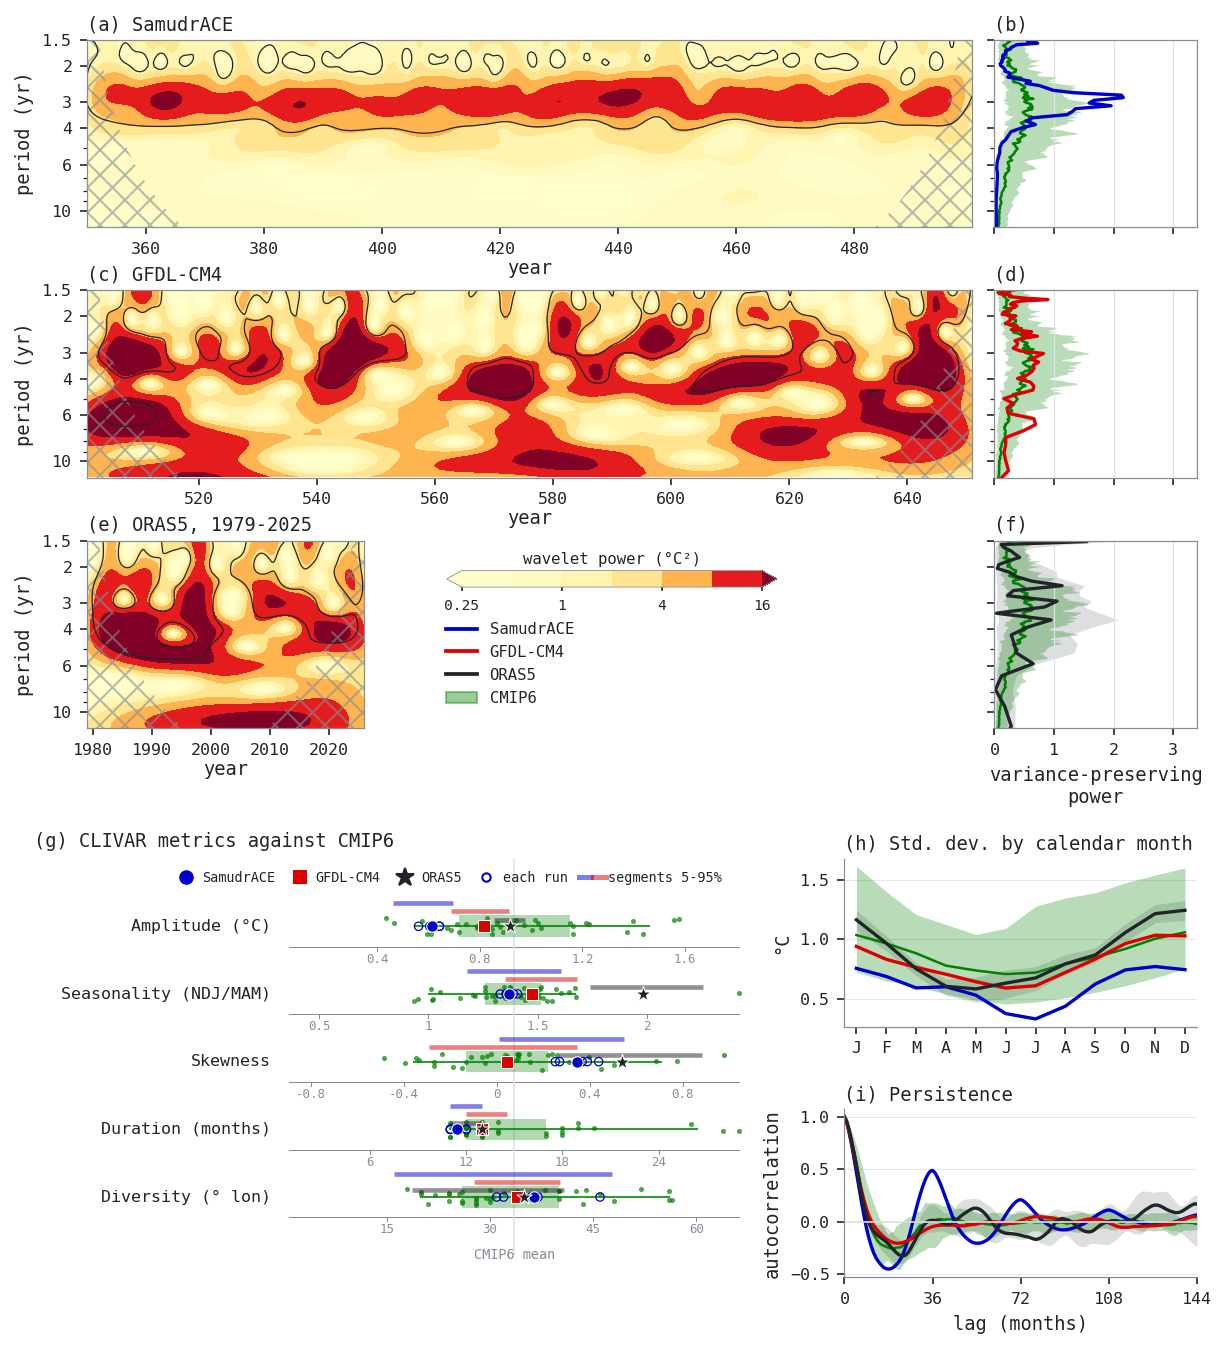

In [3]:
records = series()
data = metrics()
boot = ps.obs_bootstrap("nino34")
c6 = cmip6_results.nino34()
periods = np.geomspace(PERIODS[0], PERIODS[1], 200)
c6_spectra = []
for r in c6.values():
    per = 1 / np.asarray(r["freq_per_year"])
    order = np.argsort(per)
    c6_spectra.append(np.interp(periods, per[order], np.asarray(r["power"])[order],
                                left=np.nan, right=np.nan))
marks = iter(ps.letters(9))

width, height = 9.6, 9.0
left, wave_w, wave_h, gap = 0.75, 5.9, 1.25, 0.42
spec_x, spec_w = left + wave_w + 0.15, 1.35
fig = plt.figure(figsize=(width, height))

def rect(x, y_top, w, h):
    return [x / width, 1 - (y_top + h) / height, w / width, h / height]

rows = [("SamudrACE", "control_0311", [records[r][0] for r in RUNS], "SamudrACE"),
        ("GFDL-CM4", "GFDL-CM4", [records["GFDL-CM4"][0]], "GFDL-CM4"),
        ("ORAS5", "ORAS5", [records["ORAS5"][0]], "ORAS5, 1979-2025")]
y = 0.3
for i, (key, record, members, label) in enumerate(rows):
    x, years, _ = records[record]
    months = x.size if key == "ORAS5" else WINDOW * 12
    w = wave_w * months / (WINDOW * 12)
    ax = fig.add_axes(rect(left, y, w, wave_h))
    t_years = years - years[0] if key == "SamudrACE" else years
    mappable = wavelet_panel(ax, [m[-months:] for m in members], t_years[-months:], label,
                             next(marks))
    ax.set_xlabel("year", labelpad=1)
    sax = fig.add_axes(rect(spec_x, y, spec_w, wave_h))
    spectrum_panel(sax, members, c6_spectra, periods, ps.COLORS[key], next(marks),
                   obs=boot if key == "ORAS5" else None)
    if i == len(rows) - 1:
        sax.tick_params(labelbottom=True)
        sax.set_xlabel("variance-preserving\npower")
    y += wave_h + gap
last_row = y - wave_h - gap

free_x = left + wave_w * 47 / WINDOW + 0.55
cax = fig.add_axes(rect(free_x, last_row + 0.2, 2.2, 0.11))
bar = fig.colorbar(mappable, cax=cax, orientation="horizontal", ticks=POWER_LEVELS[::2],
                   format="%g")
bar.ax.set_title("wavelet power (°C²)", fontsize=plt.rcParams["font.size"] - 1.5, pad=3)
bar.ax.tick_params(labelsize=plt.rcParams["font.size"] - 2, length=2)
bar.outline.set_linewidth(0.4)
handles = [plt.Line2D([], [], color=ps.COLORS["SamudrACE"], lw=1.8,
                      label="SamudrACE"),
           plt.Line2D([], [], color=ps.COLORS["GFDL-CM4"], lw=1.8, label="GFDL-CM4"),
           plt.Line2D([], [], color=ps.COLORS["ORAS5"], lw=1.8, label="ORAS5"),
           plt.Rectangle((0, 0), 1, 1, fc=ps.COLORS["CMIP6"], alpha=0.4,
                         ec=ps.COLORS["CMIP6"], label="CMIP6")]
lax = fig.add_axes(rect(free_x - 0.1, last_row + 0.45, 3.0, wave_h - 0.45))
lax.axis("off")
lax.legend(handles=handles, loc="upper left", frameon=False, ncol=1,
           fontsize=plt.rcParams["font.size"] - 1.5)

y_bottom = y + 0.3
bottom_h = height - y_bottom - 0.6
right = spec_x + spec_w
col_w = 2.35
scorecard_panel(fig.add_axes(rect(2.0, y_bottom + 0.15, right - col_w - 0.6 - 2.0,
                                  bottom_h - 0.15)), data,
                next(marks))

by_month, curves = {}, {}
for key, recs in (("SamudrACE", RUNS), ("GFDL-CM4", ("GFDL-CM4",)), ("ORAS5", ("ORAS5",))):
    vals = []
    for r in recs:
        x, _, month = records[r]
        vals.append([np.nanstd(x[month == m]) for m in range(1, 13)])
    by_month[key] = np.mean(vals, axis=0)
    curves[key] = np.mean([acf(records[r][0]) for r in recs], axis=0)
small_h = (bottom_h - 0.55) / 2
month_panel(fig.add_axes(rect(right - col_w, y_bottom + 0.15, col_w, small_h)), by_month,
            [r["phase_lock_std"] for r in c6.values()], next(marks),
            obs=boot.get("std_by_month"))
acf_panel(fig.add_axes(rect(right - col_w, y_bottom + 0.15 + small_h + 0.55, col_w, small_h)),
          curves, [r["acf"][:145] for r in c6.values()], next(marks), obs=boot.get("acf"))

ps.save(fig, Path("../figures/enso_characteristics"))

## Figure 3: spring predictability barrier

In [4]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import plotstyle as ps

ps.apply()

In [5]:
DATA = Path("../data")
MONTHS = "JFMAMJJASOND"
ENTRIES = ["SamudrACE", "GFDL-CM4", "ORAS5", "CMIP6"]

In [6]:
res = json.loads((DATA / "spring_barrier.json").read_text())
cmip6 = {k: v for k, v in res.items() if k.startswith("CMIP6_")}
ps.ENSEMBLES["CMIP6"] = list(cmip6)

def stack(key, field):
    return np.array([res[m][field] for m in ps.members(key) if m in res])

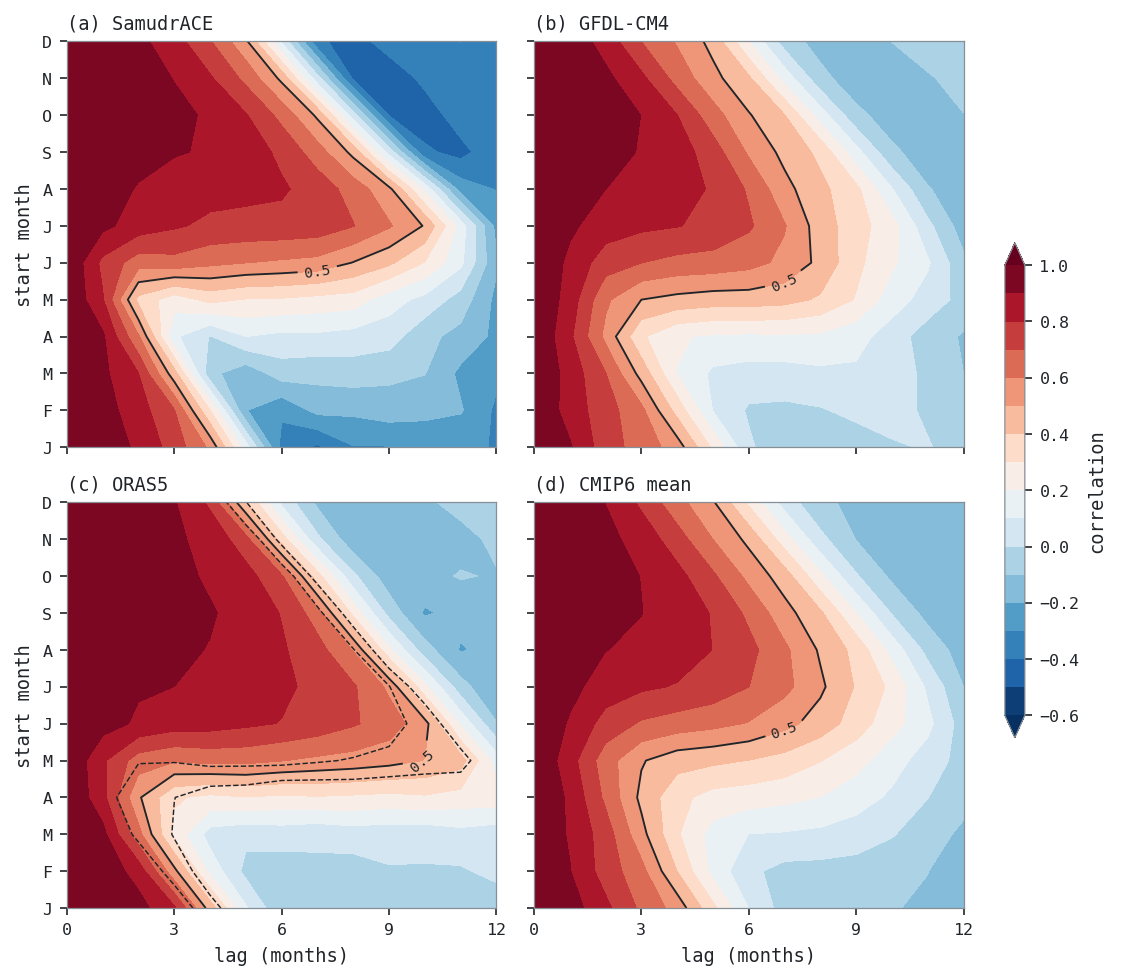

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(7.4, 6.6), sharex=True, sharey=True)
marks = ps.letters(4)
levels = np.arange(-0.6, 1.01, 0.1)
lags = np.arange(13)
for ax, key, mark in zip(axes.ravel(), ENTRIES, marks):
    r = stack(key, "r").mean(0)
    cf = ax.contourf(lags, np.arange(12), r, levels=levels, cmap="RdBu_r", extend="both")
    cs = ax.contour(lags, np.arange(12), r, levels=[0.5], colors=ps.INK, linewidths=0.9)
    ax.clabel(cs, fmt="%.1f", fontsize=7)
    if key == "ORAS5" and "r_5_95" in res["ORAS5"]:
        for bound in res["ORAS5"]["r_5_95"]:
            ax.contour(lags, np.arange(12), np.asarray(bound), levels=[0.5], colors=ps.INK,
                       linewidths=0.7, linestyles="--")
    ax.set_yticks(np.arange(12))
    ax.set_yticklabels(list(MONTHS))
    ax.set_xticks(np.arange(0, 13, 3))
    ps.panel_label(ax, ps.LABELS[key] if key != "CMIP6" else "CMIP6 mean", mark)
for ax in axes[1]:
    ax.set_xlabel("lag (months)")
for ax in axes[:, 0]:
    ax.set_ylabel("start month")
fig.tight_layout(rect=(0, 0, 0.9, 1))
cax = fig.add_axes([0.91, 0.25, 0.018, 0.5])
fig.colorbar(cf, cax=cax, ticks=np.arange(-0.6, 1.01, 0.2), label="correlation")

ps.save(fig, Path("../figures/spring_barrier"))

## Figure 4: ENSO and the zonal SST gradient

In [8]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import plotstyle as ps
from scipy import stats

ps.apply()

In [9]:
DATA = Path("../data")
ENTRIES = ["SamudrACE", "GFDL-CM4", "CMIP6"]
MEAN_WINDOW = 40
CORR_WINDOW = 60
GRID = np.linspace(-1, 1, 101)


def zscore(x) -> np.ndarray:
    x = np.asarray(x)
    return (x - x.mean()) / x.std()

In [10]:
res = json.loads((DATA / "decadal.json").read_text())
ps.ENSEMBLES["CMIP6"] = [k for k in res if k.startswith("CMIP6_")]

def members(key):
    return [m for m in ps.members(key) if m in res and "correlation" in res[m]]

rows = [(m, "SamudrACE", f"SamudrACE {m.removeprefix('control_')}")
        for m in members("SamudrACE")] + [("GFDL-CM4", "GFDL-CM4", "GFDL-CM4")]
marks = ps.letters(len(rows) + 2)

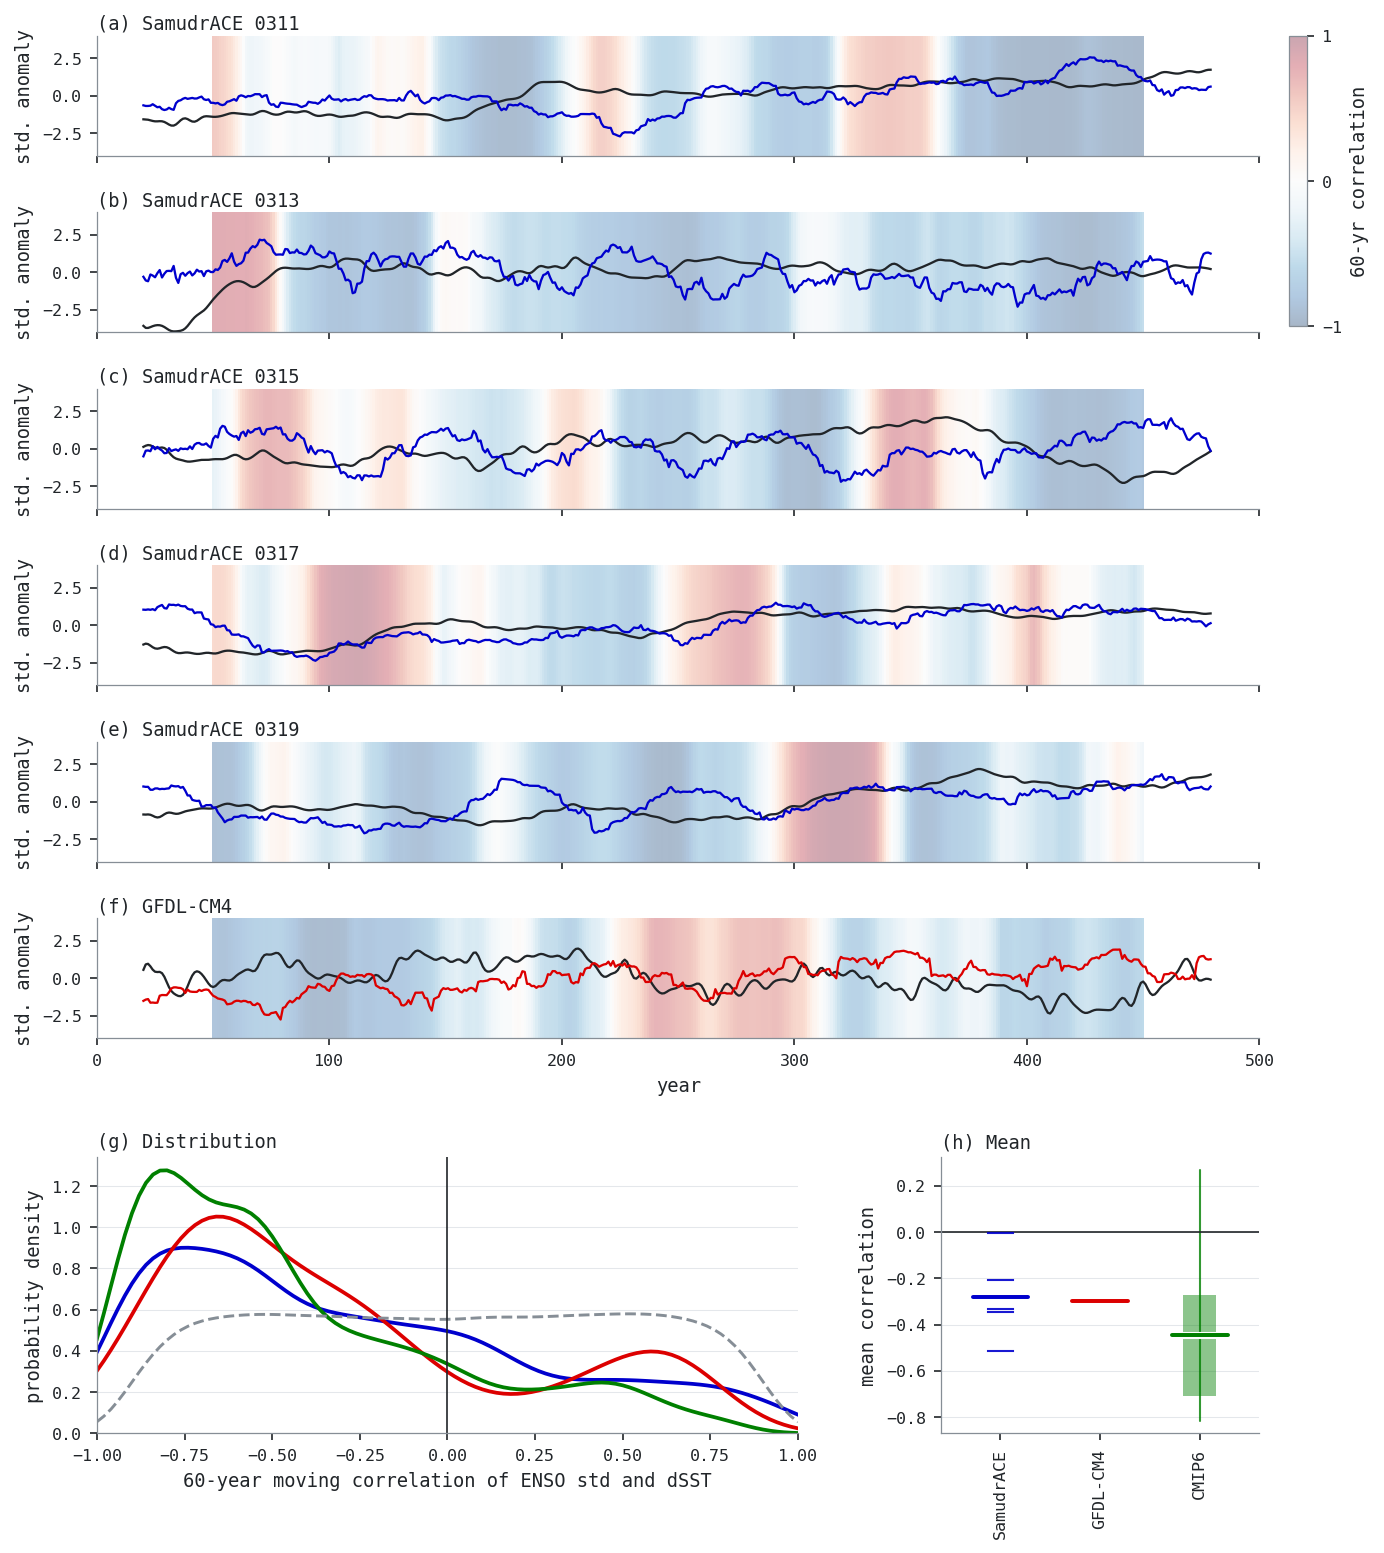

In [11]:
fig = plt.figure(figsize=(10.0, 1.35 * len(rows) + 4.0))
lim = np.ceil(max(np.abs(zscore(res[k][f])).max() for k, _, _ in rows
                  for f in ("dsst_mean", "enso_std")))
gs = fig.add_gridspec(len(rows) + 2, 2, height_ratios=[1] * len(rows) + [0.05, 2.3],
                      width_ratios=[2.2, 1], hspace=0.45, wspace=0.28)
top = None
for i, (key, entry, label) in enumerate(rows):
    r = res[key]
    ax = fig.add_subplot(gs[i, :], sharex=top)
    top = top or ax
    corr = np.asarray(r["correlation"])
    centre = np.arange(corr.size) + MEAN_WINDOW / 2 + CORR_WINDOW / 2
    edges = np.append(centre - 0.5, centre[-1] + 0.5)
    shade = ax.pcolormesh(edges, [-lim, lim], corr[None, :], cmap="RdBu_r", vmin=-1, vmax=1,
                          alpha=0.35, shading="flat", zorder=0, rasterized=True)
    years = np.arange(len(r["dsst_mean"])) + MEAN_WINDOW / 2
    ax.plot(years, zscore(r["dsst_mean"]), color=ps.INK, lw=1.1, zorder=2)
    ax.plot(years, zscore(r["enso_std"]), color=ps.COLORS[entry], lw=1.1, zorder=3)
    ax.set_ylim(-lim, lim)
    ax.set_ylabel("std. anomaly")
    ps.panel_label(ax, label, marks[i])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if i < len(rows) - 1:
        ax.tick_params(labelbottom=False)
top.set_xlim(0, max(len(res[k]["dsst_mean"]) for k, _, _ in rows) + MEAN_WINDOW)
fig.axes[len(rows) - 1].set_xlabel("year")
cax = fig.add_axes([0.92, 0.72, 0.012, 0.16])
fig.colorbar(shade, cax=cax, ticks=[-1, 0, 1], label="60-yr correlation")

ax = fig.add_subplot(gs[-1, 0])
for key in ENTRIES:
    corr = np.concatenate([res[m]["correlation"] for m in members(key)])
    ax.plot(GRID, stats.gaussian_kde(corr)(GRID), color=ps.COLORS[key], lw=1.8)
red = np.mean([res[m]["red_density"] for k in ENTRIES for m in members(k)], axis=0)
ax.plot(GRID, red, color=ps.MUTED, lw=1.4, ls="--")
ax.axvline(0, color=ps.INK, lw=0.8)
ax.set_xlim(-1, 1)
ax.set_ylim(bottom=0)
ax.set_xlabel("60-year moving correlation of ENSO std and dSST")
ax.set_ylabel("probability density")
ps.panel_label(ax, "Distribution", marks[-2])
ps.tidy(ax)

bx = fig.add_subplot(gs[-1, 1])
for i, key in enumerate(ENTRIES):
    values = [res[m]["mean_correlation"] for m in members(key)]
    if key == "CMIP6":
        ps.strip(bx, i, [np.mean(values)], ps.COLORS[key], spread=values, points=False)
    else:
        ps.strip(bx, i, values, ps.COLORS[key])
bx.axhline(0, color=ps.INK, lw=0.8)
ps.category_axis(bx, ENTRIES, rotation=90)
bx.set_ylabel("mean correlation")
ps.panel_label(bx, "Mean", marks[-1])
ps.tidy(bx)

ps.save(fig, Path("../figures/decadal"))